# Interpretabilidad y análisis de errores del modelo seleccionado

Este notebook desarrolla el objetivo específico 3 del proyecto: analizar el desempeño del modelo seleccionado en cada nivel de severidad, con énfasis en su capacidad para no subestimar los casos severos, e identificar mediante técnicas de interpretabilidad los indicadores con mayor contribución a sus estimaciones.

El modelo seleccionado es la configuración elegida en `03_busqueda_modelos.ipynb`: un modelo lineal regularizado (ElasticNet) en la formulación de regresión con umbrales, que estima el SII como un valor continuo y lo convierte en un nivel con tres umbrales. Se entrena con el conjunto principal de predictores, que reúne las variables demográficas, las variables físicas tabulares y el resumen de la actigrafía. Su evaluación usa validación cruzada anidada: cinco particiones externas estratificadas por SII, repetidas cinco veces. En cada partición externa, una validación interna de tres particiones elige los hiperparámetros del modelo, la estrategia de tratamiento de los faltantes y el exponente de ponderación α de los niveles. Este notebook no entrena modelos nuevos: reconstruye esa misma evaluación a partir del registro de la configuración seleccionada, carga sus predicciones y sus 25 modelos ajustados, y comprueba que reproducen el QWK registrado.

En un tamizaje, subestimar a un participante con uso problemático moderado o severo es más costoso que remitir a uno que no lo necesita. Por eso el QWK, que penaliza igual los errores hacia arriba y hacia abajo, se complementa con el desempeño por nivel y con un escenario de remisión. El notebook se organiza así:

1. Datos, particiones y modelos de la configuración seleccionada.
2. Desempeño por nivel de severidad: matriz de confusión, recall por nivel, tasa de subestimación y distribución de los casos severos entre los niveles asignados.
3. Escenario de tamizaje: remisión de todo participante con nivel estimado moderado o severo.
4. Contribución de las variables, con valores SHAP, y estabilidad de su orden entre repeticiones.
5. Errores por sexo y por grupo de edad.
6. Tablas exportadas y conclusiones.

Todas las salidas son agregadas: ninguna tabla contiene filas por participante ni identificadores.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from scipy import stats

from piu_severity.config import FIGURES_DIR, INTERIM_DATA_DIR, TABLES_DIR
from piu_severity.data.clean import clean_values
from piu_severity.data.load import list_actigraphy_ids, load_train
from piu_severity.evaluation.inference import (
    SEVERE_LEVEL,
    SEVERE_RECALL_MAX_SD,
    assigned_level_distribution,
    level_hits_by_repeat,
    participant_bootstrap_ci,
    participant_hit_rates,
)
from piu_severity.evaluation.interpretation import (
    DESCRIPTIVE_TOP_K,
    STABILITY_MIN_SPEARMAN,
    STABILITY_TOP_K,
    coefficient_signs,
    explain_folds,
    importance_by_repeat,
    instrument_group,
    order_is_stable,
    original_variable,
    ranking_stability,
    stack_contributions,
    top_targets,
    variable_instrument,
)
from piu_severity.evaluation.metrics import (
    SII_LEVELS,
    UNDERESTIMATION_LEVELS,
    as_levels,
    underestimation_rate,
)
from piu_severity.evaluation.persistence import (
    CACHE_VERSION,
    clear_pipeline_memory,
    run_configurations_cached,
)
from piu_severity.evaluation.reporting import metric_summary
from piu_severity.evaluation.screening import (
    REFERRAL_LEVEL,
    level_referral_by_repeat,
    participant_bootstrap_screening,
    participant_referral_rates,
    referral_consistency,
    screening_by_repeat,
)
from piu_severity.evaluation.selection import chosen_value_counts
from piu_severity.evaluation.subgroups import (
    AGE_GROUPS,
    age_group,
    subgroup_metrics_by_repeat,
    subgroup_summary,
)
from piu_severity.evaluation.validation import (
    N_OUTER_REPEATS,
    N_OUTER_SPLITS,
    mean_confusion_matrix,
    outer_splits,
    summarize_by_repeat,
)
from piu_severity.features.actigraphy import (
    load_actigraphy_summary,
    usable_actigraphy_mask,
)
from piu_severity.features.build import build_analytic_dataset
from piu_severity.features.groups import TARGET_COLUMN, experiment_feature_sets
from piu_severity.models.pipelines import available_workers
from piu_severity.models.registry import check_result, load_record, rebuild_task
from piu_severity.visualization.figures import save_figure

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# Figuras y tablas del notebook, en carpetas con su nombre.
FIGURAS = FIGURES_DIR / "04_interpretabilidad_errores"
TABLAS = TABLES_DIR / "04_interpretabilidad_errores"
# Caché de evaluaciones del notebook 03: guarda las predicciones y los modelos
# ajustados de la configuración seleccionada. Está bajo data/interim, que git
# ignora, porque contiene predicciones por participante.
CARPETA_CACHE = INTERIM_DATA_DIR / "03_busqueda_modelos" / "cache"
# Caché de Pipeline(memory=...) de este notebook: solo se usa si hay que volver a
# ajustar alguna partición, y se libera al final.
CARPETA_MEMORIA = (
    INTERIM_DATA_DIR
    / "04_interpretabilidad_errores"
    / "pipeline_memory"
    / f"v{CACHE_VERSION}"
)

# Con True se vuelve a ajustar la evaluación aunque exista en el caché.
RECALCULAR = False
# Procesos en paralelo si hay que ajustar particiones: todos los núcleos menos dos.
N_PROCESOS = available_workers("linear", os.cpu_count())

NIVELES_SII = {0: "ninguno", 1: "leve", 2: "moderado", 3: "severo"}
NOMBRES_CONJUNTOS = {"main": "principal"}
NOMBRES_ALGORITMOS = {"linear": "lineal regularizado (ElasticNet)"}
NOMBRES_FORMULACIONES = {"threshold_regression": "regresión con umbrales"}
NOMBRES_ESTRATEGIAS = {"simple": "simple con indicadores", "iterative": "iterativa"}
NOMBRES_GRILLAS = {"original": "original", "extended": "ampliada"}
NOMBRES_GRUPOS = {
    "demographic": "demográfico",
    "physical": "físico tabular",
    "actigraphy": "actigrafía",
}

## 1. Datos, particiones y modelos de la configuración seleccionada

Esta sección reconstruye el conjunto analítico y las particiones externas con las mismas funciones del paquete que usó la búsqueda de modelos. Primero verifica que reproducen las cifras de la Entrega 2: 2.736 participantes con SII, 34 de ellos severos, y 36 predictores en el conjunto principal.

Luego lee el registro de la configuración seleccionada (`models/selected_configuration.json`) y reconstruye su evaluación con la misma firma: datos, particiones, grilla, semillas y versiones de las bibliotecas. Si la firma no coincide, la reconstrucción falla. Las predicciones y el modelo ajustado de cada partición externa se cargan del caché de evaluaciones. Si el caché no existe, la evaluación se ajusta de nuevo y se comprueba que su QWK medio no difiera del registrado en más de 0,005.

Por último, se verifica que cada participante tenga exactamente una predicción por repetición y que su nivel real coincida con el del conjunto analítico. Esa correspondencia es la que permite cruzar las predicciones con el sexo y la edad en la sección 5.

In [3]:
# Conjunto analítico: participantes con SII, con las reglas de limpieza y el
# resumen de actigrafía del análisis exploratorio.
train = load_train()
etiquetados = train[train[TARGET_COLUMN].notna()].reset_index(drop=True)
analitico = build_analytic_dataset(
    clean_values(etiquetados), load_actigraphy_summary(list_actigraphy_ids())
)
y = as_levels(analitico[TARGET_COLUMN])
conjuntos = experiment_feature_sets(analitico.columns)

# Cifras de la Entrega 2 que el conjunto debe reproducir.
N_ETIQUETADOS_ENTREGA_2 = 2_736
N_SEVEROS_ENTREGA_2 = 34
N_PREDICTORES_PRINCIPAL_ENTREGA_2 = 36
assert len(analitico) == N_ETIQUETADOS_ENTREGA_2
assert analitico["id"].is_unique
assert int((y == SEVERE_LEVEL).sum()) == N_SEVEROS_ENTREGA_2
assert len(conjuntos["main"]) == N_PREDICTORES_PRINCIPAL_ENTREGA_2

# Particiones externas: cinco estratificadas por SII, repetidas cinco veces con
# la semilla 42 + r en la repetición r; son las mismas de la búsqueda.
particiones = outer_splits(y)
assert len(particiones) == N_OUTER_SPLITS * N_OUTER_REPEATS

distribucion_sii = (
    pd.Series(y)
    .map(NIVELES_SII)
    .value_counts()
    .reindex(NIVELES_SII.values())
    .rename_axis("SII")
    .to_frame("participantes")
)
distribucion_sii["%"] = (100 * distribucion_sii["participantes"] / len(y)).round(1)

# Predictores del conjunto principal por grupo, con la actigrafía aparte.
predictores_por_grupo = (
    pd.Series(
        [
            NOMBRES_GRUPOS[instrument_group(variable_instrument(c))]
            for c in conjuntos["main"]
        ]
    )
    .value_counts()
    .reindex(NOMBRES_GRUPOS.values())
    .rename_axis("grupo")
    .to_frame("predictores")
)
display(distribucion_sii)
predictores_por_grupo

,participantes,%
SII,,
ninguno,1594,58.3
leve,730,26.7
moderado,378,13.8
severo,34,1.2


,predictores
grupo,
demográfico,3
físico tabular,30
actigrafía,3


In [4]:
# Registro de la configuración seleccionada: la entrada "evaluation" es la
# evaluación de la selección guardada con sus modelos ajustados.
registro = load_record()
entrada = registro["selected"]["evaluation"]
configuracion = entrada["config"]
assert entrada["name_suffix"].endswith("__models")

pd.Series(
    {
        "algoritmo": NOMBRES_ALGORITMOS[configuracion["algorithm"]],
        "formulación": NOMBRES_FORMULACIONES[configuracion["formulation"]],
        "conjunto de predictores": NOMBRES_CONJUNTOS[configuracion["feature_set"]],
        "grilla de hiperparámetros": NOMBRES_GRILLAS[registro["selected"]["grid"]],
        "particiones externas registradas": entrada["n_folds"],
        "QWK medio registrado": round(entrada["mean_qwk"], 3),
    },
    name="configuración seleccionada",
).to_frame()

,configuración seleccionada
algoritmo,lineal regularizado (ElasticNet)
formulación,regresión con umbrales
conjunto de predictores,principal
grilla de hiperparámetros,original
particiones externas registradas,25
QWK medio registrado,0.365


In [5]:
# Reconstrucción de la evaluación con la firma del registro y carga del caché:
# predicciones y modelo ajustado de cada partición externa.
tarea = rebuild_task(
    entrada,
    analitico[conjuntos[configuracion["feature_set"]]],
    y,
    particiones,
    memory=str(CARPETA_MEMORIA),
    keep_estimators=True,
)
inicio = time.perf_counter()
seleccionada = run_configurations_cached(
    [tarea],
    cache_dir=CARPETA_CACHE,
    n_jobs=N_PROCESOS,
    force=RECALCULAR,
    verbose=5,
)[tarea.name]
print(f"Minutos en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f}")

# El resultado reproduce el registrado, hay un modelo por partición y cada
# participante tiene una predicción por repetición, con su nivel real.
diferencia_qwk = check_result(seleccionada, entrada)
assert all(seleccionada.estimators[(s.repeat, s.fold)] is not None for s in particiones)
predicciones = seleccionada.predictions
assert len(predicciones) == len(y) * N_OUTER_REPEATS
assert (predicciones.groupby("repeat")["position"].nunique() == len(y)).all()
assert np.array_equal(
    predicciones["y_true"].to_numpy(), y[predicciones["position"].to_numpy()]
)

conteo = seleccionada.counts()
print(
    f"Particiones cargadas: {conteo['loaded']}; ajustadas de nuevo: {conteo['computed']}"
)
print(
    f"QWK medio: {seleccionada.folds['qwk'].mean():.4f} "
    f"(diferencia con el registro: {diferencia_qwk:+.4f})"
)

Minutos en esta ejecución: 0.0
Particiones cargadas: 25; ajustadas de nuevo: 0
QWK medio: 0.3652 (diferencia con el registro: +0.0000)


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


In [6]:
# Tratamiento elegido por la validación interna en cada partición externa: la
# estrategia de faltantes y el exponente de ponderación α de los niveles.
parametros = list(seleccionada.folds["best_params"])
estrategias = chosen_value_counts(parametros, "preprocess__strategy")
exponentes = chosen_value_counts(parametros, "model__weight_power")
assert estrategias.idxmax() == registro["selected"]["most_frequent_strategy"]
assert estrategias.sum() == exponentes.sum() == len(particiones)

pd.concat(
    {
        "estrategia de faltantes": estrategias.rename(index=NOMBRES_ESTRATEGIAS),
        "exponente de ponderación α": exponentes.rename(index=lambda a: f"α = {a:g}"),
    },
    names=["hiperparámetro", "valor"],
).to_frame("particiones externas")

particiones externas
hiperparámetro             valor                                       
estrategia de faltantes    iterativa                                 20
                           simple con indicadores                     5
exponente de ponderación α α = 0.5                                   25

### Conclusión

- **Conjunto analítico.** Reproduce las cifras de la Entrega 2. Hay 2.736 participantes con SII: el 58,3 % en el nivel ninguno, el 26,7 % en leve, el 13,8 % en moderado y el 1,2 % en severo, que son 34 casos. El conjunto principal tiene 36 predictores: 3 demográficos, 30 físicos tabulares y 3 de actigrafía.
- **Evaluación reconstruida.** La firma coincide con la del registro y las 25 particiones externas se cargan del caché sin volver a ajustarse. El QWK medio es 0,365, igual al registrado, y cada participante tiene exactamente una predicción por repetición.
- **Tratamiento elegido.** La validación interna eligió la imputación iterativa en 20 de las 25 particiones y la imputación simple con indicadores de ausencia en las otras 5. El exponente de ponderación α fue 0,5 en las 25.

Como el tratamiento de los faltantes cambia entre particiones, los 25 modelos no comparten exactamente los mismos predictores transformados: los cinco con imputación simple incluyen un indicador de ausencia por instrumento. Esto se tiene en cuenta al agregar las contribuciones de las variables en la sección 4.

## 2. Desempeño por nivel de severidad

El QWK resume el acuerdo entre el nivel real y el asignado, pero es simétrico: subestimar o sobrestimar en la misma magnitud cuesta lo mismo. Para un tamizaje importa también dónde se equivoca el modelo, sobre todo en los niveles moderado y severo. Esta sección lo describe así:

- **Métricas por repetición.** En cada repetición, cada participante se predice exactamente una vez. Por eso, el recall de cada nivel y la tasa de subestimación se calculan sobre las predicciones de la repetición, y el QWK es la media de sus cinco particiones. Se reportan la media y la desviación estándar entre las cinco repeticiones; esa desviación describe la estabilidad frente a la partición de los datos.
- **Tasa de subestimación.** Es la proporción de participantes con SII moderado o severo a los que se asigna un nivel inferior al real:

$$
\text{subestimación} = \frac{\#\{i : y_i \in \{2, 3\},\ \hat{y}_i < y_i\}}{\#\{i : y_i \in \{2, 3\}\}}
$$

  Se reporta también solo para el nivel moderado, como descripción. En el nivel severo, toda asignación incorrecta es una subestimación, así que su tasa es uno menos su recall. En su lugar se reporta a qué niveles se asignan los participantes severos.
- **Incertidumbre.** Las repeticiones reutilizan a los mismos participantes, así que la desviación entre repeticiones no mide la incertidumbre de generalización. Para cada métrica por nivel se calcula además un intervalo del 95 % remuestreando participantes, cada uno con sus cinco repeticiones, 10.000 veces.
- **Nivel severo.** Con 34 casos, su recall se reporta por repetición con su intervalo de Wilson del 95 %, y se aplica la regla de estabilidad de la formulación: si la desviación estándar entre repeticiones superara 0,10 (unos tres casos), la evaluación se extendería a diez repeticiones. Se reporta también cuántos participantes severos reciben el mismo nivel en todas las repeticiones.

In [7]:
# Métricas por repetición: el QWK es la media de las cinco particiones de la
# repetición; el recall por nivel y la subestimación se calculan sobre sus
# predicciones, donde cada participante se estima una vez.
por_repeticion = summarize_by_repeat(seleccionada.folds, predicciones)
NIVEL_MODERADO = UNDERESTIMATION_LEVELS[0]
por_repeticion["underestimation_moderate"] = pd.Series(
    {
        repeticion: underestimation_rate(
            grupo["y_true"], grupo["y_pred"], levels=(NIVEL_MODERADO,)
        )
        for repeticion, grupo in predicciones.groupby("repeat")
    }
)

# Las cifras agregadas coinciden con las del registro de la configuración.
seleccion_registrada = registro["selected"]
assert np.isclose(
    por_repeticion["qwk"].std(), seleccion_registrada["qwk_sd_between_repeats"]
)
assert np.isclose(
    por_repeticion["underestimation"].mean(),
    seleccion_registrada["underestimation_moderate_or_severe"],
)
assert np.isclose(
    por_repeticion[f"recall_{SEVERE_LEVEL}"].mean(),
    seleccion_registrada["severe_recall"],
)

ETIQUETAS_METRICAS = {
    "qwk": "QWK",
    **{f"recall_{nivel}": f"recall {NIVELES_SII[nivel]}" for nivel in SII_LEVELS},
    "underestimation": "subestimación moderado o severo",
    "underestimation_moderate": "subestimación moderado",
}
resumen_repeticiones = por_repeticion.agg(["mean", "std"]).rename(
    index={"mean": "media", "std": "desviación"}
)
(
    pd.concat([por_repeticion.rename_axis("repetición"), resumen_repeticiones])
    .rename(columns=ETIQUETAS_METRICAS)
    .round(3)
)

,QWK,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo,subestimación moderado
0,0.357,0.664,0.371,0.339,0.0,0.689,0.661
1,0.365,0.651,0.426,0.315,0.0,0.711,0.685
2,0.375,0.672,0.322,0.426,0.0,0.609,0.574
3,0.370,0.651,0.433,0.288,0.0,0.735,0.712
4,0.359,0.651,0.370,0.360,0.0,0.670,0.640
media,0.365,0.658,0.384,0.346,0.0,0.683,0.654
desviación,0.007,0.010,0.046,0.052,0.0,0.048,0.052


In [8]:
# Intervalo del 95 % de cada métrica por nivel, remuestreando participantes con
# sus cinco repeticiones (10.000 remuestreos). El recall de un nivel es la media
# de las tasas de acierto de sus participantes, y la subestimación, la media de
# sus tasas de asignación a un nivel inferior.
def tasas_subestimacion(niveles: tuple[int, ...]) -> pd.Series:
    """Proporción de repeticiones en que cada participante recibe un nivel inferior."""
    casos = predicciones[predicciones["y_true"].isin(niveles)]
    inferior = (casos["y_pred"] < casos["y_true"]).astype(float)
    return inferior.groupby(casos["position"]).mean()


tasas = {
    **{
        f"recall_{nivel}": participant_hit_rates(predicciones, nivel)
        for nivel in SII_LEVELS
    },
    "underestimation": tasas_subestimacion(UNDERESTIMATION_LEVELS),
    "underestimation_moderate": tasas_subestimacion((NIVEL_MODERADO,)),
}
# La media de las tasas por participante es la media entre repeticiones.
for metrica, tasas_metrica in tasas.items():
    assert np.isclose(tasas_metrica.mean(), por_repeticion[metrica].mean())

resumen_desempeno = metric_summary(
    por_repeticion,
    intervals={
        metrica: participant_bootstrap_ci(tasas_metrica)
        for metrica, tasas_metrica in tasas.items()
    },
    sizes={metrica: len(tasas_metrica) for metrica, tasas_metrica in tasas.items()},
)
ETIQUETAS_RESUMEN = {
    "mean": "media",
    "std_between_repeats": "desviación entre repeticiones",
    "interval_low": "intervalo 95 % inferior",
    "interval_high": "intervalo 95 % superior",
    "n": "participantes",
}
(
    resumen_desempeno.rename(index=ETIQUETAS_METRICAS, columns=ETIQUETAS_RESUMEN)
    .rename_axis("métrica")
    .round(3)
)

,media,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior,participantes
métrica,,,,,
QWK,0.365,0.007,NaN,NaN,<NA>
recall ninguno,0.658,0.010,0.636,0.680,1594
recall leve,0.384,0.046,0.355,0.414,730
recall moderado,0.346,0.052,0.303,0.389,378
recall severo,0.000,0.000,0.000,0.000,34
subestimación moderado o severo,0.683,0.048,0.643,0.722,412
subestimación moderado,0.654,0.052,0.611,0.697,378


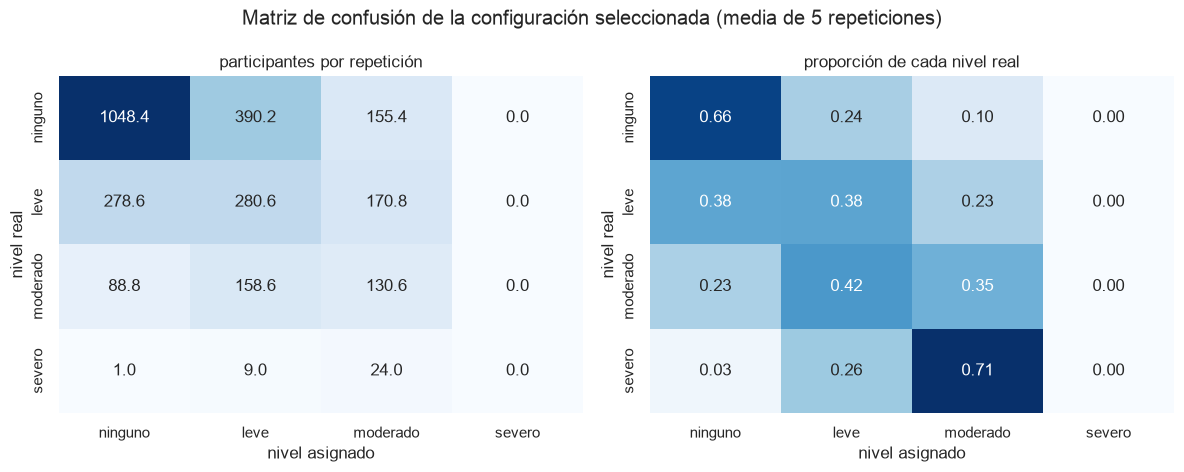

In [9]:
# Matriz de confusión promediada entre repeticiones: en conteos (participantes
# por celda en una repetición) y normalizada por fila, donde la diagonal es el
# recall de cada nivel.
etiquetas_niveles = list(NIVELES_SII.values())
matrices = {
    "participantes por repetición": mean_confusion_matrix(
        predicciones, normalize=False
    ),
    "proporción de cada nivel real": mean_confusion_matrix(
        predicciones, normalize=True
    ),
}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, (titulo, matriz), formato in zip(
    ejes, matrices.items(), (".1f", ".2f"), strict=True
):
    sns.heatmap(
        matriz.set_axis(etiquetas_niveles, axis=0).set_axis(etiquetas_niveles, axis=1),
        annot=True,
        fmt=formato,
        cmap="Blues",
        cbar=False,
        ax=eje,
    )
    eje.set_title(titulo)
    eje.set_xlabel("nivel asignado")
    eje.set_ylabel("nivel real")
fig.suptitle(
    "Matriz de confusión de la configuración seleccionada (media de 5 repeticiones)"
)
fig.tight_layout()
save_figure(fig, "matriz_confusion", FIGURAS)
plt.show()

In [10]:
# Nivel severo: aciertos de cada repetición con su intervalo de Wilson y regla
# de estabilidad de la formulación (desviación entre repeticiones mayor que 0,10).
aciertos_severo = level_hits_by_repeat(predicciones, SEVERE_LEVEL)
desviacion_severo = aciertos_severo["recall"].std()
severo_inestable = bool(desviacion_severo > SEVERE_RECALL_MAX_SD)
assert severo_inestable == seleccion_registrada["severe_recall_unstable"]
print(
    f"Recall severo: {aciertos_severo['recall'].mean():.3f}; desviación entre "
    f"repeticiones {desviacion_severo:.3f} (límite {SEVERE_RECALL_MAX_SD:g}); "
    f"inestable: {severo_inestable}"
)

# Distribución de los participantes severos entre los niveles asignados, en cada
# repetición y en promedio.
severos = predicciones[predicciones["y_true"] == SEVERE_LEVEL]
distribucion_por_repeticion = (
    severos.groupby("repeat")["y_pred"]
    .value_counts(normalize=True)
    .unstack(fill_value=0.0)
    .reindex(columns=list(SII_LEVELS), fill_value=0.0)
)
assert np.allclose(
    distribucion_por_repeticion.mean().to_numpy(),
    assigned_level_distribution(predicciones, SEVERE_LEVEL)
    .reindex(list(SII_LEVELS), fill_value=0.0)
    .to_numpy(),
)
distribucion_severo = pd.concat(
    [
        distribucion_por_repeticion.rename_axis("repetición"),
        distribucion_por_repeticion.agg(["mean", "std"]).rename(
            index={"mean": "media", "std": "desviación"}
        ),
    ]
).rename(columns=NIVELES_SII)
display(
    aciertos_severo.rename(
        columns={
            "cases": "casos severos",
            "hits": "aciertos",
            "recall": "recall",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    )
    .rename_axis("repetición")
    .round(3)
)
distribucion_severo.rename_axis(columns="nivel asignado").round(3)

Recall severo: 0.000; desviación entre repeticiones 0.000 (límite 0.1); inestable: False


,casos severos,aciertos,recall,Wilson inferior,Wilson superior
repetición,,,,,
0,34,0,0.0,0.0,0.102
1,34,0,0.0,0.0,0.102
2,34,0,0.0,0.0,0.102
3,34,0,0.0,0.0,0.102
4,34,0,0.0,0.0,0.102


nivel asignado,ninguno,leve,moderado,severo
0,0.029,0.265,0.706,0.0
1,0.059,0.265,0.676,0.0
2,0.029,0.176,0.794,0.0
3,0.029,0.324,0.647,0.0
4,0.000,0.294,0.706,0.0
media,0.029,0.265,0.706,0.0
desviación,0.021,0.055,0.055,0.0


In [11]:
# Estabilidad de la asignación de cada participante severo entre repeticiones:
# cuántos reciben siempre el mismo nivel, y cuál.
niveles_por_severo = severos.groupby("position")["y_pred"]
mismo_nivel = niveles_por_severo.nunique() == 1
print(
    f"Participantes severos con el mismo nivel en las {N_OUTER_REPEATS} "
    f"repeticiones: {int(mismo_nivel.sum())} de {mismo_nivel.size}"
)
(
    niveles_por_severo.first()[mismo_nivel]
    .map(NIVELES_SII)
    .value_counts()
    .reindex(etiquetas_niveles, fill_value=0)
    .rename_axis("nivel asignado en todas las repeticiones")
    .to_frame("participantes severos")
)

Participantes severos con el mismo nivel en las 5 repeticiones: 23 de 34


,participantes severos
nivel asignado en todas las repeticiones,
ninguno,0
leve,4
moderado,19
severo,0


### Conclusión

- **Acuerdo global.** El QWK medio es 0,365 y varía poco entre repeticiones (de 0,357 a 0,375, con una desviación de 0,007).
- **Recall por nivel.** El modelo reconoce mejor el nivel ninguno (recall de 0,658; intervalo del 95 % de 0,636 a 0,680) que los niveles con uso problemático: 0,384 en leve (0,355 a 0,414) y 0,346 en moderado (0,303 a 0,389). Los recall de leve y moderado son también los que más varían entre repeticiones, con desviaciones de 0,046 y 0,052.
- **Subestimación.** El 68,3 % de los participantes moderados o severos recibe un nivel inferior al real (intervalo del 95 % de 64,3 % a 72,2 %; desviación entre repeticiones de 0,048). Como los moderados son 378 de esos 412 participantes, la tasa la determina sobre todo ese nivel: el 65,4 % de los moderados se subestima. Según la matriz de confusión, el 42 % de los moderados se asigna al nivel leve y el 23 % al nivel ninguno, es decir, dos niveles por debajo.
- **Sobrestimación.** Los errores hacia arriba también son frecuentes: el 24 % de los participantes sin uso problemático se asigna al nivel leve y el 10 % al moderado, y el 23 % de los leves se asigna al moderado.
- **Nivel severo.** Ningún participante recibe el nivel severo, de ningún nivel real y en ninguna repetición, así que el recall severo es 0 en las cinco. La desviación entre repeticiones es 0, por debajo del límite de 0,10, de modo que la regla de estabilidad no exige extender la evaluación. El intervalo por remuestreo de participantes es [0, 0], pero no informa sobre la incertidumbre, porque todas las tasas de acierto son 0. La cota informativa es la de Wilson: con 0 aciertos en 34 casos, el recall severo podría llegar a 0,102.
- **A dónde van los severos.** En promedio, el 70,6 % de los participantes severos se asigna al nivel moderado (de 64,7 % a 79,4 % según la repetición), el 26,5 % al leve y el 2,9 % al nivel ninguno. La asignación es estable: 23 de los 34 reciben el mismo nivel en las cinco repeticiones (19 siempre moderado y 4 siempre leve), y los otros 11 cambian de nivel según la partición.
- **Sesgo optimista.** La configuración se seleccionó con estas mismas particiones externas, así que estas métricas tienen el sesgo optimista propio de reportar el desempeño con los datos que intervinieron en la elección. Se espera que sea pequeño, porque la regla de selección no eligió la configuración por tener el mayor QWK, sino por su tasa de subestimación y su complejidad entre las de QWK similar.

El modelo nunca asigna el nivel severo, pero ubica a la mayoría de los severos en el nivel inmediatamente inferior. Ese error es el que el QWK penaliza menos y, en un tamizaje, es también el que menos importa si la remisión empieza en el nivel moderado. La sección 3 examina esa consecuencia directamente.

## 3. Escenario de tamizaje

Para valorar el potencial de los indicadores como insumo de un tamizaje, las predicciones se traducen a una decisión de remisión: se remite a todo participante con nivel estimado moderado o severo. Un participante es positivo si su SII real es moderado o severo. Con los verdaderos positivos ($VP$), falsos negativos ($FN$), falsos positivos ($FP$) y verdaderos negativos ($VN$), se reportan:

$$
\text{recall} = \frac{VP}{VP + FN}, \qquad
\text{especificidad} = \frac{VN}{VN + FP}, \qquad
\text{valor predictivo positivo} = \frac{VP}{VP + FP}, \qquad
\text{proporción remitida} = \frac{VP + FP}{n}
$$

La regla de remisión y la forma de reportar su variabilidad quedaron fijadas en el paquete antes de calcular estos resultados:

- **Estabilidad e incertidumbre.** Las métricas se calculan sobre las predicciones de cada repetición, y se reportan su media y su desviación entre repeticiones. Además, se calcula un intervalo del 95 % remuestreando participantes, cada uno con sus cinco repeticiones, 10.000 veces. Ese intervalo se calcula sobre los conteos acumulados de las cinco repeticiones. Para el recall, la especificidad y la proporción remitida, esa estimación es igual a la media entre repeticiones. Para el valor predictivo positivo puede diferir un poco, porque su denominador cambia entre repeticiones.
- **Remisión por nivel real.** Para cada nivel se reporta qué proporción de sus participantes se remite. En el nivel ninguno, esa proporción es la de remisiones innecesarias; en los niveles moderado y severo, es la de casos detectados.
- **Casos severos.** Se reporta cuántos de los 34 participantes severos se remiten en cada repetición, con su intervalo de Wilson, y cuántos se remiten en todas las repeticiones, en ninguna o solo en algunas. Esta cifra responde si el modelo, aunque no asigne el nivel severo, logra que esos participantes lleguen a una evaluación.

No existe un umbral clínico de desempeño aceptable para este escenario, así que los resultados se leen como evidencia exploratoria y no como una validación clínica.

In [12]:
# Escenario de tamizaje: se remite a todo participante con nivel estimado
# moderado o severo. La regla y la forma de reportar su variabilidad quedaron
# fijadas en el paquete antes de calcular estos resultados.
assert REFERRAL_LEVEL == NIVEL_MODERADO
tamizaje_por_repeticion = screening_by_repeat(predicciones)
bootstrap_tamizaje = participant_bootstrap_screening(predicciones)
# Sobre los conteos acumulados, la estimación coincide con la media entre
# repeticiones en todas las métricas salvo el valor predictivo positivo.
for metrica in ("recall", "specificity", "referred_share"):
    assert np.isclose(
        bootstrap_tamizaje.loc[metrica, "estimate"],
        tamizaje_por_repeticion[metrica].mean(),
    )

n_positivos = int((y >= REFERRAL_LEVEL).sum())
resumen_tamizaje = metric_summary(
    tamizaje_por_repeticion,
    intervals={
        metrica: (
            bootstrap_tamizaje.loc[metrica, "interval_low"],
            bootstrap_tamizaje.loc[metrica, "interval_high"],
        )
        for metrica in tamizaje_por_repeticion.columns
    },
    sizes={
        "recall": n_positivos,
        "specificity": len(y) - n_positivos,
        "referred_share": len(y),
    },
)
ETIQUETAS_TAMIZAJE = {
    "recall": "recall",
    "specificity": "especificidad",
    "ppv": "valor predictivo positivo",
    "referred_share": "proporción remitida",
}
display(
    pd.concat(
        [
            tamizaje_por_repeticion.rename_axis("repetición"),
            tamizaje_por_repeticion.agg(["mean", "std"]).rename(
                index={"mean": "media", "std": "desviación"}
            ),
        ]
    )
    .rename(columns=ETIQUETAS_TAMIZAJE)
    .round(3)
)
(
    resumen_tamizaje.rename(index=ETIQUETAS_TAMIZAJE, columns=ETIQUETAS_RESUMEN)
    .rename_axis("métrica")
    .round(3)
)

,recall,especificidad,valor predictivo positivo,proporción remitida
0,0.369,0.854,0.309,0.180
1,0.345,0.880,0.336,0.154
2,0.456,0.826,0.318,0.216
3,0.318,0.889,0.338,0.142
4,0.388,0.849,0.314,0.186
media,0.375,0.860,0.323,0.176
desviación,0.052,0.025,0.013,0.029


,media,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior,participantes
métrica,,,,,
recall,0.375,0.052,0.334,0.418,412
especificidad,0.860,0.025,0.847,0.872,2324
valor predictivo positivo,0.323,0.013,0.283,0.361,<NA>
proporción remitida,0.176,0.029,0.163,0.188,2736


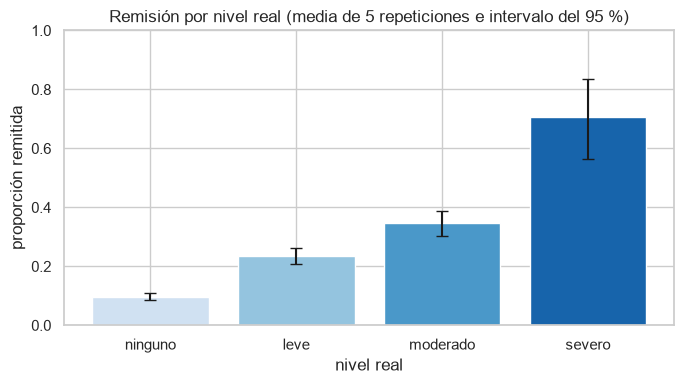

,participantes,remitidos por repetición (media),proporción remitida,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior
nivel real,,,,,,
ninguno,1594,155.4,0.097,0.017,0.085,0.111
leve,730,170.8,0.234,0.043,0.208,0.261
moderado,378,130.6,0.346,0.052,0.303,0.389
severo,34,24.0,0.706,0.055,0.565,0.835


In [13]:
# Proporción remitida de cada nivel real, por repetición, con su intervalo del
# 95 % por remuestreo de participantes.
remision_por_repeticion = {
    nivel: level_referral_by_repeat(predicciones, nivel) for nivel in SII_LEVELS
}
filas = {}
for nivel, remision in remision_por_repeticion.items():
    bajo, alto = participant_bootstrap_ci(
        participant_referral_rates(predicciones, nivel)
    )
    filas[NIVELES_SII[nivel]] = {
        "participantes": int(remision["cases"].iloc[0]),
        "remitidos por repetición (media)": remision["referred"].mean(),
        "proporción remitida": remision["share"].mean(),
        "desviación entre repeticiones": remision["share"].std(),
        "intervalo 95 % inferior": bajo,
        "intervalo 95 % superior": alto,
    }
remision_por_nivel = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    "nivel real"
)

fig, eje = plt.subplots(figsize=(7, 4))
eje.bar(
    remision_por_nivel.index,
    remision_por_nivel["proporción remitida"],
    yerr=[
        remision_por_nivel["proporción remitida"]
        - remision_por_nivel["intervalo 95 % inferior"],
        remision_por_nivel["intervalo 95 % superior"]
        - remision_por_nivel["proporción remitida"],
    ],
    color=sns.color_palette("Blues", len(remision_por_nivel)),
    capsize=4,
)
eje.set_ylim(0, 1)
eje.set_xlabel("nivel real")
eje.set_ylabel("proporción remitida")
eje.set_title("Remisión por nivel real (media de 5 repeticiones e intervalo del 95 %)")
fig.tight_layout()
save_figure(fig, "remision_por_nivel", FIGURAS)
plt.show()
remision_por_nivel.round(3)

In [14]:
# Participantes severos remitidos en cada repetición, de 34, con su intervalo de
# Wilson, y cuántos participantes moderados y severos se remiten en todas las
# repeticiones, en ninguna o solo en algunas.
display(
    remision_por_repeticion[SEVERE_LEVEL]
    .rename(
        columns={
            "cases": "casos severos",
            "referred": "remitidos",
            "share": "proporción remitida",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    )
    .rename_axis("repetición")
    .round(3)
)
(
    pd.DataFrame(
        {
            NIVELES_SII[nivel]: referral_consistency(
                participant_referral_rates(predicciones, nivel)
            )
            for nivel in UNDERESTIMATION_LEVELS
        }
    )
    .T.rename(
        columns={
            "always": "remitidos en todas las repeticiones",
            "never": "en ninguna",
            "sometimes": "en algunas",
            "participants": "participantes",
        }
    )
    .rename_axis("nivel real")
)

,casos severos,remitidos,proporción remitida,Wilson inferior,Wilson superior
repetición,,,,,
0,34,24,0.706,0.538,0.832
1,34,23,0.676,0.508,0.809
2,34,27,0.794,0.632,0.897
3,34,22,0.647,0.479,0.785
4,34,24,0.706,0.538,0.832


,remitidos en todas las repeticiones,en ninguna,en algunas,participantes
nivel real,,,,
moderado,92,195,91,378
severo,19,7,8,34


### Conclusión

- **Proporción remitida.** La regla remite al 17,6 % de los participantes (intervalo del 95 % de 16,3 % a 18,8 %), unos 481 por repetición.
- **Detección de casos.** El recall es 0,375 (de 0,334 a 0,418): de cada ocho participantes con SII moderado o severo, se remiten tres. Varía entre repeticiones de 0,318 a 0,456, con una desviación de 0,052. Como los moderados son 378 de los 412 positivos, este recall depende sobre todo de ellos.
- **Especificidad y valor predictivo positivo.** La especificidad es 0,860 (de 0,847 a 0,872) y el valor predictivo positivo, 0,323 (de 0,283 a 0,361). Uno de cada tres remitidos tiene un SII moderado o severo. De los demás, unos 155 por repetición no tienen uso problemático y unos 171 lo tienen leve.
- **Comparación con una remisión al azar.** Si se remitiera al azar a la misma proporción de participantes, se detectaría en promedio el 17,6 % de los positivos, y el valor predictivo positivo sería igual a la prevalencia: 412 de 2.736, es decir, 15,1 %. El modelo duplica ambas cifras.
- **Remisión por nivel real.** La proporción remitida crece con la severidad: 9,7 % de los participantes sin uso problemático, 23,4 % de los leves, 34,6 % de los moderados y 70,6 % de los severos.
- **Casos severos.** Aunque el modelo no asigna el nivel severo, remite en promedio a 24 de los 34 participantes severos, porque los ubica en el nivel moderado. Por repetición, remite entre 22 y 27, con intervalos de Wilson que van de 0,48 a 0,90; el intervalo por remuestreo de participantes va de 0,565 a 0,835. Por participante, 19 de los 34 severos se remiten en las cinco repeticiones, 7 en ninguna y 8 solo en algunas.
- **Casos moderados.** En cambio, más de la mitad de los moderados (195 de 378) no se remite en ninguna repetición, y solo 92 se remiten en todas.
- **Los dos errores del tamizaje.** Las cifras miden los dos riesgos que tendría usar un modelo de capacidad limitada con menores. Dos de cada tres remisiones serían innecesarias, con el riesgo de estigmatizar a quien no tiene el problema. Además, 7 participantes severos y 195 moderados no se remitirían en ninguna repetición, lo que podría retrasar una atención necesaria.

En un escenario que remite desde el nivel moderado, que el modelo no asigne el nivel severo pesa menos de lo que sugiere su recall severo nulo: siete de cada diez severos llegan a la remisión. El límite principal del escenario está en los moderados, que son la mayoría de los positivos y de los que se remite solo uno de cada tres. Con 34 casos severos, la proporción de severos remitidos tiene un intervalo amplio. Además, como no existe un umbral clínico de desempeño aceptable, estas cifras son evidencia exploratoria y no permiten usar el modelo como herramienta diagnóstica.

## 4. Contribución de las variables (SHAP)

Esta sección identifica qué variables pesan más en las estimaciones del modelo seleccionado y en qué dirección, con valores SHAP.

- **Salida explicada.** Como el modelo es una regresión con umbrales, se explica la estimación continua del SII, antes de los umbrales. Los umbrales cambian de una partición a otra, así que las contribuciones explican cómo el modelo ordena a los participantes en esa escala continua, no directamente el nivel que asigna.
- **Cálculo.** Para un modelo lineal con predictores tratados como independientes, la contribución de la variable transformada $j$ al participante $x$ es exacta:

$$
\phi_j(x) = \beta_j \, (x_j - \bar{x}_j),
$$

  donde $\beta_j$ es el coeficiente del ElasticNet y $\bar{x}_j$ es la media de la variable en toda la partición de entrenamiento. La suma de las contribuciones más el valor base reproduce la estimación continua, y se verifica en cada partición. Cada modelo explica sus filas de evaluación, así que cada participante se explica una vez por repetición, con un modelo que no lo vio.
- **Agregación.** Las contribuciones se suman con su signo dentro de cada variable original: las columnas de la codificación one-hot de la temporada de inscripción forman una sola variable. Los indicadores de ausencia, que solo existen en las cinco particiones con imputación simple, se reportan como variables propias («ausencia de» el instrumento) y valen cero en las demás. Las contribuciones también se suman por instrumento y por grupo: demográfico, físico tabular y actigrafía. La importancia de una variable en una repetición es la media del valor absoluto de su contribución, y se reportan su media y su desviación entre repeticiones.
- **Estabilidad del orden.** El criterio quedó fijado en el paquete antes de calcular las contribuciones. El orden se considera estable si la correlación de Spearman entre las importancias de cada par de repeticiones es al menos 0,9 en los diez pares, y si las cinco variables más importantes son las mismas en las cinco repeticiones. Además, se reporta en cuántas repeticiones cada variable está entre las diez más importantes.
- **Dirección.** Es el signo del coeficiente de cada predictor transformado en las particiones en que aparece. Las variables numéricas pasan por Yeo-Johnson y estandarización, que son transformaciones crecientes, así que el signo indica también la dirección en la escala original. Se muestra además la distribución de las contribuciones en una repetición.

Las contribuciones describen el comportamiento del modelo, no efectos causales, y su lectura tiene dos límites. Primero, varias variables físicas están correlacionadas con la edad, y con predictores correlacionados el reparto de la contribución entre ellos no es único. Por eso se recalcula la correlación de cada variable física con la edad, y la agregación por grupo es la lectura más robusta. Segundo, los valores de quienes no tienen un instrumento son imputados, de modo que en ellos SHAP describe cómo el modelo usa valores imputados y no mediciones reales. Por eso, la contribución de la actigrafía se compara entre los participantes con una serie utilizable y aquellos con valores imputados.

In [15]:
# Contribuciones SHAP de cada partición externa: su modelo explica sus filas de
# evaluación, con toda su partición de entrenamiento como fondo.
X_principal = analitico[conjuntos["main"]]
inicio = time.perf_counter()
explicaciones = explain_folds(seleccionada.estimators, particiones, X_principal)
print(f"Segundos en esta ejecución: {time.perf_counter() - inicio:.1f}")

# Las contribuciones son exactas: sumadas al valor base reproducen la estimación
# continua, y los umbrales de cada partición reproducen los niveles evaluados.
for particion in particiones:
    clave = (particion.repeat, particion.fold)
    explicacion = explicaciones[clave]
    modelo = seleccionada.estimators[clave].named_steps["model"]
    continua = modelo.predict_continuous(explicacion["values"])
    assert np.allclose(
        explicacion["contributions"].sum(axis="columns") + explicacion["base_value"],
        continua,
    )
    evaluadas = predicciones[
        (predicciones["repeat"] == particion.repeat)
        & (predicciones["fold"] == particion.fold)
    ].set_index("position")
    assert np.array_equal(
        modelo.predict(explicacion["values"]),
        evaluadas.loc[particion.test, "y_pred"].to_numpy(),
    )
print(f"Contribuciones verificadas en las {len(particiones)} particiones externas.")

Segundos en esta ejecución: 3.0
Contribuciones verificadas en las 25 particiones externas.


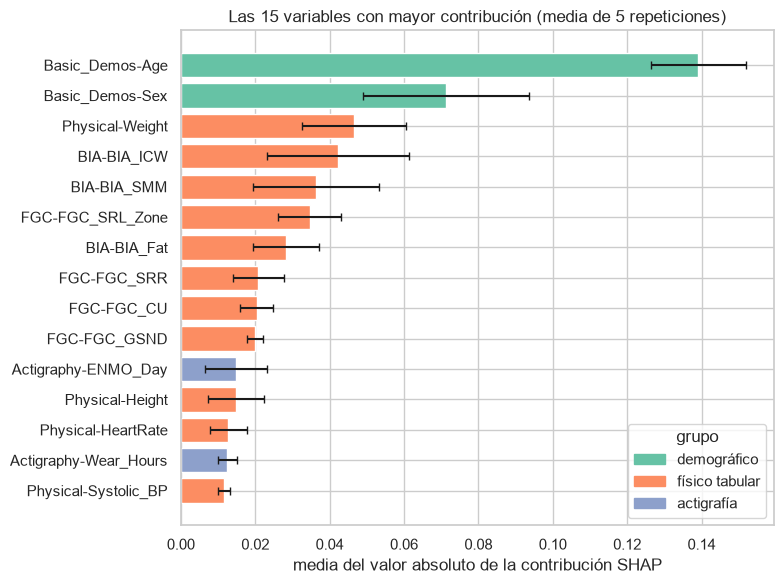

,grupo,importancia media,desviación entre repeticiones,puesto medio,repeticiones en el top 10
variable,,,,,
Basic_Demos-Age,demográfico,0.139,0.013,1.0,5
Basic_Demos-Sex,demográfico,0.071,0.022,2.4,5
Physical-Weight,físico tabular,0.047,0.014,4.2,5
BIA-BIA_ICW,físico tabular,0.042,0.019,5.4,4
BIA-BIA_SMM,físico tabular,0.036,0.017,5.8,4
FGC-FGC_SRL_Zone,físico tabular,0.035,0.008,4.8,5
BIA-BIA_Fat,físico tabular,0.028,0.009,7.2,5
FGC-FGC_SRR,físico tabular,0.021,0.007,10.0,4
FGC-FGC_CU,físico tabular,0.020,0.004,9.4,3


In [16]:
# Importancia de cada variable original en cada repetición: media del valor
# absoluto de su contribución, sumada con su signo sobre sus columnas
# transformadas. Los indicadores de ausencia quedan como variables propias.
def nombre_variable(variable: str) -> str:
    """Nombre de una variable original o de un indicador de ausencia."""
    if variable in conjuntos["main"]:
        return variable
    return f"ausencia de {variable_instrument(variable)}"


contribuciones_variables = stack_contributions(explicaciones, "variable")
importancia = importance_by_repeat(contribuciones_variables)
assert (contribuciones_variables.groupby(level="repeat").size() == len(analitico)).all()

en_top = top_targets(importancia, DESCRIPTIVE_TOP_K).sum()
importancia_variables = (
    pd.DataFrame(
        {
            "grupo": [
                NOMBRES_GRUPOS[instrument_group(variable_instrument(v))]
                for v in importancia.columns
            ],
            "importancia media": importancia.mean(),
            "desviación entre repeticiones": importancia.std(),
            "puesto medio": importancia.rank(axis="columns", ascending=False).mean(),
            f"repeticiones en el top {DESCRIPTIVE_TOP_K}": en_top,
        }
    )
    .sort_values("importancia media", ascending=False)
    .rename(index=nombre_variable)
    .rename_axis("variable")
)

N_FIGURA = 15
COLORES_GRUPOS = dict(
    zip(NOMBRES_GRUPOS.values(), sns.color_palette("Set2"), strict=False)
)
principales = importancia_variables.head(N_FIGURA)
fig, eje = plt.subplots(figsize=(8, 6))
eje.barh(
    principales.index[::-1],
    principales["importancia media"][::-1],
    xerr=principales["desviación entre repeticiones"][::-1],
    color=[COLORES_GRUPOS[g] for g in principales["grupo"][::-1]],
    capsize=3,
)
eje.set_xlabel("media del valor absoluto de la contribución SHAP")
eje.set_title(
    f"Las {N_FIGURA} variables con mayor contribución (media de 5 repeticiones)"
)
eje.legend(
    [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES_GRUPOS.values()],
    COLORES_GRUPOS.keys(),
    title="grupo",
    loc="lower right",
)
fig.tight_layout()
save_figure(fig, "importancia_variables", FIGURAS)
plt.show()
importancia_variables.round(3)

In [17]:
# Estabilidad del orden de importancia entre repeticiones, con el criterio fijado
# en el paquete antes de calcular las contribuciones.
estabilidad = order_is_stable(importancia)
print(
    f"Spearman mínimo entre repeticiones: {estabilidad['min_spearman']:.3f} "
    f"(mediana {estabilidad['median_spearman']:.3f}; criterio "
    f"≥ {STABILITY_MIN_SPEARMAN:g})"
)
print(
    f"Mismas {STABILITY_TOP_K} variables principales en las {N_OUTER_REPEATS} "
    f"repeticiones: {estabilidad['same_top_k']}"
)
print(f"El orden de importancia se mantiene: {estabilidad['stable']}")

ranking_por_repeticion = pd.DataFrame(
    {
        repeticion: [
            nombre_variable(v) for v in fila.sort_values(ascending=False).index
        ][:STABILITY_TOP_K]
        for repeticion, fila in importancia.iterrows()
    },
    index=pd.RangeIndex(1, STABILITY_TOP_K + 1, name="puesto"),
).rename_axis(columns="repetición")
display(ranking_por_repeticion)
ranking_stability(importancia).rename(
    columns={
        "repeat_a": "repetición a",
        "repeat_b": "repetición b",
        "spearman": "Spearman",
    }
).round(3)

Spearman mínimo entre repeticiones: 0.694 (mediana 0.780; criterio ≥ 0.9)
Mismas 5 variables principales en las 5 repeticiones: False
El orden de importancia se mantiene: False


repetición,0,1,2,3,4
puesto,,,,,
1,Basic_Demos-Age,Basic_Demos-Age,Basic_Demos-Age,Basic_Demos-Age,Basic_Demos-Age
2,Physical-Weight,Basic_Demos-Sex,Basic_Demos-Sex,BIA-BIA_ICW,Basic_Demos-Sex
3,Basic_Demos-Sex,Physical-Weight,BIA-BIA_SMM,Basic_Demos-Sex,BIA-BIA_SMM
4,BIA-BIA_ICW,BIA-BIA_ICW,Physical-Weight,FGC-FGC_SRL_Zone,FGC-FGC_SRL_Zone
5,FGC-FGC_SRL_Zone,FGC-FGC_SRL_Zone,Actigraphy-ENMO_Day,BIA-BIA_SMM,Physical-Weight


,repetición a,repetición b,Spearman
0,0,1,0.884
1,0,2,0.743
2,0,3,0.764
3,0,4,0.829
4,1,2,0.840
5,1,3,0.797
6,1,4,0.803
7,2,3,0.730
8,2,4,0.694
9,3,4,0.762


In [18]:
# Importancia agregada por instrumento y por grupo: las contribuciones de sus
# variables e indicadores se suman con su signo antes del valor absoluto.
tablas_agregadas = {}
for nivel, nombre in (("instrument", "instrumento"), ("group", "grupo")):
    importancia_nivel = importance_by_repeat(stack_contributions(explicaciones, nivel))
    tablas_agregadas[nombre] = (
        pd.DataFrame(
            {
                "importancia media": importancia_nivel.mean(),
                "desviación entre repeticiones": importancia_nivel.std(),
                "puesto medio": importancia_nivel.rank(
                    axis="columns", ascending=False
                ).mean(),
            }
        )
        .sort_values("importancia media", ascending=False)
        .rename_axis(nombre)
    )
tablas_agregadas["grupo"] = tablas_agregadas["grupo"].rename(index=NOMBRES_GRUPOS)
display(tablas_agregadas["instrumento"].round(3))
tablas_agregadas["grupo"].round(3)

,importancia media,desviación entre repeticiones,puesto medio
instrumento,,,
Basic_Demos,0.152,0.017,1.0
BIA,0.101,0.019,2.2
Physical,0.072,0.013,2.8
FGC,0.060,0.007,4.0
Actigraphy,0.026,0.009,5.0
PAQ,0.005,0.002,6.0


,importancia media,desviación entre repeticiones,puesto medio
grupo,,,
físico tabular,0.202,0.009,1.0
demográfico,0.152,0.017,2.0
actigrafía,0.026,0.009,3.0


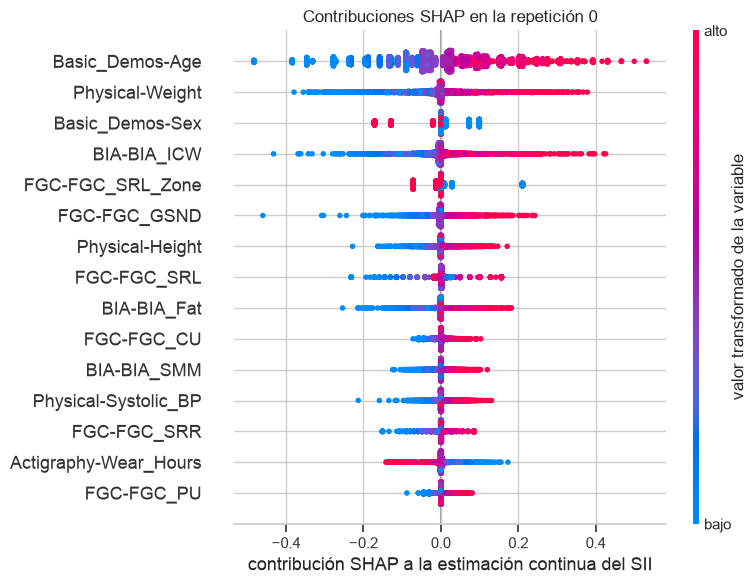

,variable,particiones con coeficiente positivo,con coeficiente negativo,con coeficiente cero,particiones en que aparece
predictor transformado,,,,,
Basic_Demos-Age,Basic_Demos-Age,25,0,0,25
Basic_Demos-Sex,Basic_Demos-Sex,0,19,6,25
Physical-Weight,Physical-Weight,18,0,7,25
BIA-BIA_ICW,BIA-BIA_ICW,15,1,9,25
BIA-BIA_SMM,BIA-BIA_SMM,19,0,6,25
FGC-FGC_SRL_Zone,FGC-FGC_SRL_Zone,0,18,7,25
BIA-BIA_Fat,BIA-BIA_Fat,18,0,7,25
FGC-FGC_SRR,FGC-FGC_SRR,17,0,8,25
FGC-FGC_CU,FGC-FGC_CU,20,0,5,25


In [19]:
# Dirección de las contribuciones: signo del coeficiente de cada predictor
# transformado en las particiones en que aparece, para las variables principales.
signos = coefficient_signs(seleccionada.estimators)
signos.insert(
    0,
    "variable",
    [nombre_variable(original_variable(p, conjuntos["main"])) for p in signos.index],
)
direccion = (
    signos[signos["variable"].isin(importancia_variables.index[:DESCRIPTIVE_TOP_K])]
    .rename(
        columns={
            "positive": "particiones con coeficiente positivo",
            "negative": "con coeficiente negativo",
            "zero": "con coeficiente cero",
            "folds": "particiones en que aparece",
        }
    )
    .rename_axis("predictor transformado")
)
direccion = direccion.loc[
    direccion["variable"]
    .map({v: i for i, v in enumerate(importancia_variables.index)})
    .sort_values(kind="stable")
    .index
]

# Contribuciones de una repetición frente al valor transformado de cada variable,
# sin la temporada (codificada en varias columnas) ni los indicadores de ausencia,
# que solo existen en algunas particiones.
REPETICION_FIGURA = 0
columnas_figura = [c for c in conjuntos["main"] if c in importancia_variables.index]
columnas_figura = [
    c for c in columnas_figura if all(c in e["values"] for e in explicaciones.values())
]
claves = [c for c in explicaciones if c[0] == REPETICION_FIGURA]
valores = pd.concat([explicaciones[c]["values"][columnas_figura] for c in claves])
contribuciones = pd.concat(
    [
        contribuciones_variables.loc[(REPETICION_FIGURA, c[1])][columnas_figura]
        for c in claves
    ]
)
fig, eje = plt.subplots(figsize=(8, 6))
shap.plots.beeswarm(
    shap.Explanation(
        values=contribuciones.to_numpy(),
        data=valores.to_numpy(),
        feature_names=columnas_figura,
    ),
    max_display=N_FIGURA,
    group_remaining_features=False,
    ax=eje,
    plot_size=None,
    show=False,
    color_bar_label="valor transformado de la variable",
)
eje.set_xlabel("contribución SHAP a la estimación continua del SII")
fig.axes[-1].set_yticklabels(["bajo", "alto"])
eje.set_title(f"Contribuciones SHAP en la repetición {REPETICION_FIGURA}")
fig.tight_layout()
save_figure(fig, "contribuciones_shap_repeticion", FIGURAS)
plt.show()
direccion

In [20]:
# Relación de las variables físicas y de actigrafía con la edad, sobre los valores
# medidos (sin imputar): correlación de Spearman y proporción de participantes con
# dato, en el orden de su importancia.
EDAD = "Basic_Demos-Age"
filas = {}
for variable in importancia_variables.index:
    if variable not in conjuntos["main"]:
        continue
    if instrument_group(variable_instrument(variable)) == "demographic":
        continue
    datos = analitico[[variable, EDAD]].dropna()
    filas[variable] = {
        "importancia media": importancia_variables.loc[variable, "importancia media"],
        "participantes con dato (%)": 100 * len(datos) / len(analitico),
        "Spearman con la edad": stats.spearmanr(datos[variable], datos[EDAD]).statistic,
    }
relacion_edad = pd.DataFrame.from_dict(filas, orient="index").rename_axis("variable")
display(relacion_edad.round(3))

# Contribución de la actigrafía según si el participante tiene una serie
# utilizable o si sus valores son imputados.
con_serie = usable_actigraphy_mask(analitico).to_numpy()
posiciones = contribuciones_variables.index.get_level_values("position")
columnas_actigrafia = [
    c
    for c in contribuciones_variables.columns
    if c in conjuntos["main"]
    and instrument_group(variable_instrument(c)) == "actigraphy"
]
actigrafia = (
    contribuciones_variables[columnas_actigrafia]
    .abs()
    .groupby(np.where(con_serie[posiciones], "serie utilizable", "imputada"))
    .mean()
)
print(
    f"Participantes sin serie de actigrafía utilizable: {100 * (1 - con_serie.mean()):.1f} %"
)
actigrafia.rename_axis("valores de actigrafía").round(3)

,importancia media,participantes con dato (%),Spearman con la edad
variable,,,
Physical-Weight,0.047,92.105,0.841
BIA-BIA_ICW,0.042,60.197,0.782
BIA-BIA_SMM,0.036,60.197,0.812
FGC-FGC_SRL_Zone,0.035,68.604,-0.219
BIA-BIA_Fat,0.028,60.197,0.630
FGC-FGC_SRR,0.021,69.920,-0.151
FGC-FGC_CU,0.020,70.139,0.595
FGC-FGC_GSND,0.020,31.725,0.608
Actigraphy-ENMO_Day,0.015,30.080,-0.540


Participantes sin serie de actigrafía utilizable: 69.9 %


,Actigraphy-ENMO_Day,Actigraphy-ENMO_Night,Actigraphy-Wear_Hours
valores de actigrafía,,,
imputada,0.011,0.005,0.007
serie utilizable,0.025,0.018,0.025


In [21]:
# Conclusiones de H2 (conjunto principal frente a la referencia demográfica) y H3
# (aporte de la actigrafía) registradas en la búsqueda de modelos, con los dos
# tratamientos de los faltantes.
pd.DataFrame(registro["hypotheses"]).rename(
    columns={
        "fixed_treatment": "tratamiento fijo",
        "treatment_chosen_in_each_fold": "tratamiento elegido en cada partición",
    }
).rename_axis("hipótesis")

,tratamiento fijo,tratamiento elegido en cada partición
hipótesis,,
H2,sin evidencia de mejora; aporte despreciable,sin evidencia de mejora; aporte despreciable
H3,sin evidencia de mejora; aporte despreciable,sin evidencia de mejora; aporte despreciable


### Conclusión

- **Contribuciones exactas.** En las 25 particiones, las contribuciones sumadas al valor base reproducen la estimación continua, y los umbrales de cada modelo reproducen los niveles evaluados.
- **Variables individuales.** La edad es la variable con mayor contribución en las cinco repeticiones, con 0,139 de media del valor absoluto. Le siguen el sexo (0,071) y un bloque de medidas de tamaño corporal, composición corporal y aptitud física:
  - el peso (0,047);
  - el agua intracelular (0,042) y la masa muscular esquelética (0,036), medidas por bioimpedancia;
  - la zona de flexibilidad del lado izquierdo (0,035);
  - la grasa corporal (0,028).

  La actigrafía aparece más abajo: el ENMO diurno ocupa en promedio el puesto 15 y está entre las diez primeras variables en una sola repetición. La temporada de inscripción y los indicadores de ausencia aportan poco, con 0,011 o menos.
- **Estabilidad del orden.** Con el criterio fijado antes de calcular las contribuciones, el orden de importancia de las variables no se mantiene entre repeticiones. El Spearman mínimo entre pares de repeticiones es 0,694 (mediana de 0,780), por debajo de 0,9, y las cinco primeras variables cambian entre repeticiones. Lo estable son los primeros puestos: la edad es la primera en las cinco repeticiones y el sexo está entre las tres primeras en las cinco. Los demás puestos de las cinco primeras rotan entre el peso, las variables de bioimpedancia, la zona de flexibilidad y, en una repetición, el ENMO diurno.
- **Por qué cambia el orden.** Las variables que rotan están muy correlacionadas con la edad: su Spearman con la edad es 0,84 en el peso, 0,78 en el agua intracelular y 0,81 en la masa muscular. Con predictores tan correlacionados, el ElasticNet reparte el peso entre ellos de forma distinta en cada partición, y a menudo anula alguno: el coeficiente del peso es cero en 7 de las 25 particiones, el del agua intracelular en 9 y el de la masa muscular en 6. Por eso, la importancia de cada variable física por separado no es una conclusión robusta.
- **Agregación por grupo e instrumento.** Por grupo, el orden sí es estable. El grupo físico tabular tiene la mayor contribución (0,202), seguido del demográfico (0,152) y de la actigrafía (0,026), en ese orden en las cinco repeticiones. Por instrumento, la bioimpedancia (0,101) supera a las medidas antropométricas y signos vitales (0,072) y a FitnessGram (0,060). Como las variables físicas reflejan sobre todo la edad, su contribución conjunta no es información independiente de ella. En la búsqueda de modelos, agregar las variables físicas a la referencia demográfica tuvo un aporte despreciable en el QWK (H2, en la celda anterior).
- **Dirección.** La edad tiene coeficiente positivo en las 25 particiones: a mayor edad, mayor estimación del SII. El valor 1 del sexo tiene coeficiente negativo en 19 particiones y cero en 6. El peso, el agua intracelular, la masa muscular y la grasa corporal tienen coeficiente positivo o cero en casi todas las particiones; la zona de flexibilidad izquierda, negativo o cero. Dos medidas del mismo constructo tienen signos opuestos: la zona de flexibilidad izquierda tiene coeficiente negativo y la flexibilidad derecha medida en pulgadas, positivo. Es otro efecto de la correlación entre predictores, no una relación interpretable.
- **Valores imputados.** El 69,9 % de los participantes no tiene una serie de actigrafía utilizable. En ellos, la contribución media de la actigrafía es menor que en quienes tienen una serie: 0,011 frente a 0,025 en el ENMO diurno, y 0,007 frente a 0,025 en las horas de uso de la pulsera. Pero no es nula, porque el modelo también usa los valores imputados, que se derivan de las demás variables.

Las contribuciones describen el comportamiento del modelo, no efectos causales. Para la condición de interpretabilidad de un tamizaje, el modelo se puede explicar de forma consistente por la edad, el sexo y el peso conjunto de cada grupo de variables. En cambio, la explicación por variables físicas individuales cambia con la partición de los datos.

## 5. Errores por sexo y por grupo de edad

Esta sección examina si los errores del modelo se distribuyen de manera desigual entre sexos y entre tres grupos de edad: 5 a 12 años, 13 a 17 años y 18 a 22 años. Los sexos y los grupos de edad se comparan por separado, sin cruzarlos, porque al cruzarlos las celdas del nivel severo tienen muy pocos casos.

- **Métricas.** Para cada subgrupo se reportan su tamaño, el número de participantes moderados o severos y de severos, el QWK, el recall por nivel, la tasa de subestimación y las métricas del escenario de tamizaje de la sección 3.
- **Cálculo.** Algunos subgrupos son pequeños: el de 18 a 22 años tiene unos 17 participantes por partición de evaluación. Por eso, todas las métricas se calculan sobre las predicciones de cada repetición, donde cada participante se estima una vez, y se reportan con su media y su desviación entre repeticiones. El QWK calculado así, con las predicciones de las cinco particiones juntas, no coincide necesariamente con la media de los QWK por partición de las secciones anteriores. Para comparar en la misma escala, se calcula de la misma forma una fila con todos los participantes.
- **Alcance.** El análisis es descriptivo: no se hacen pruebas de hipótesis entre subgrupos. El grupo de 18 a 22 años se mantiene en el análisis, porque el alcance del proyecto no se restringió, pero tiene solo 84 participantes y 4 severos, así que sus resultados no se sobreinterpretan.

El SII proviene del reporte de los padres. Por eso, las diferencias entre subgrupos pueden reflejar también lo que los padres observan del uso de internet de sus hijos según la edad o el sexo, y no solo diferencias en el comportamiento del modelo.

In [22]:
# Subgrupos por sexo y por grupo de edad, indexados por la posición del
# participante en el conjunto analítico, la misma de las predicciones.
SEXO = "Basic_Demos-Sex"
CODIGOS_SEXO = {0: "hombres", 1: "mujeres"}
ETIQUETAS_EDAD = {
    grupo: f"{inicio_grupo} a {fin_grupo} años"
    for grupo, (inicio_grupo, fin_grupo) in AGE_GROUPS.items()
}
participantes = analitico.reset_index(drop=True)
grupos = {
    "sexo": pd.Series(
        pd.Categorical(
            participantes[SEXO].map(CODIGOS_SEXO),
            categories=list(CODIGOS_SEXO.values()),
            ordered=True,
        )
    ),
    "grupo de edad": age_group(participantes[EDAD]).cat.rename_categories(
        ETIQUETAS_EDAD
    ),
}
assert all(serie.notna().all() for serie in grupos.values())

# Tamaños de la Entrega 2 (Tabla 4): participantes, porcentaje con SII moderado
# o severo y casos severos. También verifican la codificación del sexo.
TAMANOS_ENTREGA_2 = {
    "hombres": (1_739, 17.4, 26),
    "mujeres": (997, 11.0, 8),
    "5 a 12 años": (2_070, 10.1, 6),
    "13 a 17 años": (582, 31.1, 24),
    "18 a 22 años": (84, 26.2, 4),
}
filas = {}
for criterio, serie in grupos.items():
    for subgrupo in serie.cat.categories:
        niveles = y[(serie == subgrupo).to_numpy()]
        filas[(criterio, subgrupo)] = {
            "participantes": len(niveles),
            "moderado o severo (%)": round(
                100 * np.isin(niveles, UNDERESTIMATION_LEVELS).mean(), 1
            ),
            "severos": int((niveles == SEVERE_LEVEL).sum()),
        }
tamanos = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    ["criterio", "subgrupo"]
)
assert {
    subgrupo: tuple(fila) for (_, subgrupo), fila in tamanos.iterrows()
} == TAMANOS_ENTREGA_2
tamanos

participantes  moderado o severo (%)  severos
criterio      subgrupo                                                   
sexo          hombres                1739                   17.4       26
              mujeres                 997                   11.0        8
grupo de edad 5 a 12 años            2070                   10.1        6
              13 a 17 años            582                   31.1       24
              18 a 22 años             84                   26.2        4

In [23]:
# Métricas de cada subgrupo en cada repetición, sobre sus predicciones, con la
# fila de todos los participantes calculada de la misma forma.
ETIQUETAS_SUBGRUPOS = {
    "qwk": "QWK",
    **{f"recall_{nivel}": f"recall {NIVELES_SII[nivel]}" for nivel in SII_LEVELS},
    "underestimation": "subestimación moderado o severo",
    "screening_recall": "recall del tamizaje",
    "referred_share": "proporción remitida",
    "n": "participantes",
    "n_moderate_or_severe": "moderados o severos",
    "n_severe": "severos",
}
por_subgrupo_repeticion = {
    criterio: subgroup_metrics_by_repeat(predicciones, serie)
    for criterio, serie in grupos.items()
}
resumen_subgrupos = pd.concat(
    {
        criterio: subgroup_summary(tabla)
        for criterio, tabla in por_subgrupo_repeticion.items()
    },
    names=["criterio", "subgrupo"],
).rename(index={"all": "todos"}, level="subgrupo")
# La fila de todos los participantes coincide en ambos criterios.
pd.testing.assert_series_equal(
    resumen_subgrupos.loc[("sexo", "todos")],
    resumen_subgrupos.loc[("grupo de edad", "todos")],
    check_names=False,
)
resumen_subgrupos = resumen_subgrupos.drop(index=("grupo de edad", "todos"))

metricas_subgrupo = [
    columna
    for columna in resumen_subgrupos.columns.get_level_values(0).unique()
    if columna not in ("n", "n_moderate_or_severe", "n_severe")
]
tamanos_subgrupo = resumen_subgrupos[["n", "n_moderate_or_severe", "n_severe"]]
tamanos_subgrupo.columns = tamanos_subgrupo.columns.get_level_values(0)
medias_subgrupo = pd.concat(
    [
        tamanos_subgrupo,
        resumen_subgrupos.xs("mean", axis="columns", level=1)[metricas_subgrupo],
    ],
    axis="columns",
)
desviaciones_subgrupo = resumen_subgrupos.xs("std", axis="columns", level=1)[
    metricas_subgrupo
]
print("Media entre repeticiones")
display(medias_subgrupo.rename(columns=ETIQUETAS_SUBGRUPOS).round(3))
print("Desviación entre repeticiones")
desviaciones_subgrupo.rename(columns=ETIQUETAS_SUBGRUPOS).round(3)

Media entre repeticiones


participantes  moderados o severos  severos  \
criterio      subgrupo                                                    
sexo          todos                  2736                  412       34   
              hombres                1739                  302       26   
              mujeres                 997                  110        8   
grupo de edad 5 a 12 años            2070                  209        6   
              13 a 17 años            582                  181       24   
              18 a 22 años             84                   22        4   

                              QWK  recall ninguno  recall leve  \
criterio      subgrupo                                           
sexo          todos         0.365           0.658        0.384   
              hombres       0.367           0.625        0.369   
              mujeres       0.338           0.706        0.414   
grupo de edad 5 a 12 años   0.264           0.767        0.404   
              13 a 17 años  0.064           0.013        0.378   
              18 a 22 años  0.002           0.000        0.093   

                            recall moderado  recall severo  \
criterio      subgrupo                                       
sexo          todos                   0.346            0.0   
              hombres                 0.378            0.0   
              mujeres                 0.257            0.0   
grupo de edad 5 a 12 años             0.071            0.0   
              13 a 17 años            0.637            0.0   
              18 a 22 años            0.900            0.0   

                            subestimación moderado o severo  \
criterio      subgrupo                                        
sexo          todos                                   0.683   
              hombres                                 0.654   
              mujeres                                 0.762   
grupo de edad 5 a 12 años                             0.931   
              13 a 17 años                            0.448   
              18 a 22 años                            0.264   

                            recall del tamizaje  proporción remitida  
criterio      subgrupo                                                
sexo          todos                       0.375                0.176  
              hombres                     0.413                0.206  
              mujeres                     0.271                0.123  
grupo de edad 5 a 12 años                 0.080                0.026  
              13 a 17 años                0.650                0.600  
              18 a 22 años                0.918                0.917

Desviación entre repeticiones


QWK  recall ninguno  recall leve  \
criterio      subgrupo                                           
sexo          todos         0.007           0.010        0.046   
              hombres       0.010           0.010        0.031   
              mujeres       0.016           0.018        0.074   
grupo de edad 5 a 12 años   0.010           0.012        0.024   
              13 a 17 años  0.018           0.006        0.104   
              18 a 22 años  0.025           0.000        0.064   

                            recall moderado  recall severo  \
criterio      subgrupo                                       
sexo          todos                   0.052            0.0   
              hombres                 0.056            0.0   
              mujeres                 0.050            0.0   
grupo de edad 5 a 12 años             0.027            0.0   
              13 a 17 años            0.094            0.0   
              18 a 22 años            0.025            0.0   

                            subestimación moderado o severo  \
criterio      subgrupo                                        
sexo          todos                                   0.048   
              hombres                                 0.051   
              mujeres                                 0.046   
grupo de edad 5 a 12 años                             0.026   
              13 a 17 años                            0.082   
              18 a 22 años                            0.020   

                            recall del tamizaje  proporción remitida  
criterio      subgrupo                                                
sexo          todos                       0.052                0.029  
              hombres                     0.057                0.030  
              mujeres                     0.047                0.031  
grupo de edad 5 a 12 años                 0.028                0.012  
              13 a 17 años                0.089                0.091  
              18 a 22 años                0.020                0.036

In [24]:
# Las cuatro métricas del escenario de tamizaje en cada subgrupo, calculadas con
# la misma regla de la sección 3 sobre las predicciones de cada repetición.
filas = {("sexo", "todos"): screening_by_repeat(predicciones)}
for criterio, serie in grupos.items():
    etiquetas = predicciones["position"].map(serie).astype(str)
    for subgrupo in serie.cat.categories:
        filas[(criterio, subgrupo)] = screening_by_repeat(
            predicciones[etiquetas == subgrupo]
        )
indice = pd.MultiIndex.from_tuples(filas, names=["criterio", "subgrupo"])
medias_tamizaje = pd.DataFrame([t.mean() for t in filas.values()], index=indice)
desviaciones_tamizaje = pd.DataFrame([t.std() for t in filas.values()], index=indice)
# El recall coincide con el recall del tamizaje de la tabla anterior.
assert np.allclose(
    medias_tamizaje["recall"], medias_subgrupo.loc[indice, "screening_recall"]
)
print("Media entre repeticiones")
display(medias_tamizaje.rename(columns=ETIQUETAS_TAMIZAJE).round(3))
print("Desviación entre repeticiones")
desviaciones_tamizaje.rename(columns=ETIQUETAS_TAMIZAJE).round(3)

Media entre repeticiones


recall  especificidad  valor predictivo positivo  \
criterio      subgrupo                                                         
sexo          todos          0.375          0.860                      0.323   
              hombres        0.413          0.837                      0.348   
              mujeres        0.271          0.896                      0.249   
grupo de edad 5 a 12 años    0.080          0.980                      0.319   
              13 a 17 años   0.650          0.423                      0.338   
              18 a 22 años   0.918          0.084                      0.263   

                            proporción remitida  
criterio      subgrupo                           
sexo          todos                       0.176  
              hombres                     0.206  
              mujeres                     0.123  
grupo de edad 5 a 12 años                 0.026  
              13 a 17 años                0.600  
              18 a 22 años                0.917

Desviación entre repeticiones


recall  especificidad  valor predictivo positivo  \
criterio      subgrupo                                                         
sexo          todos          0.052          0.025                      0.013   
              hombres        0.057          0.024                      0.007   
              mujeres        0.047          0.029                      0.027   
grupo de edad 5 a 12 años    0.028          0.010                      0.042   
              13 a 17 años   0.089          0.094                      0.014   
              18 a 22 años   0.020          0.055                      0.016   

                            proporción remitida  
criterio      subgrupo                           
sexo          todos                       0.029  
              hombres                     0.030  
              mujeres                     0.031  
grupo de edad 5 a 12 años                 0.012  
              13 a 17 años                0.091  
              18 a 22 años                0.036

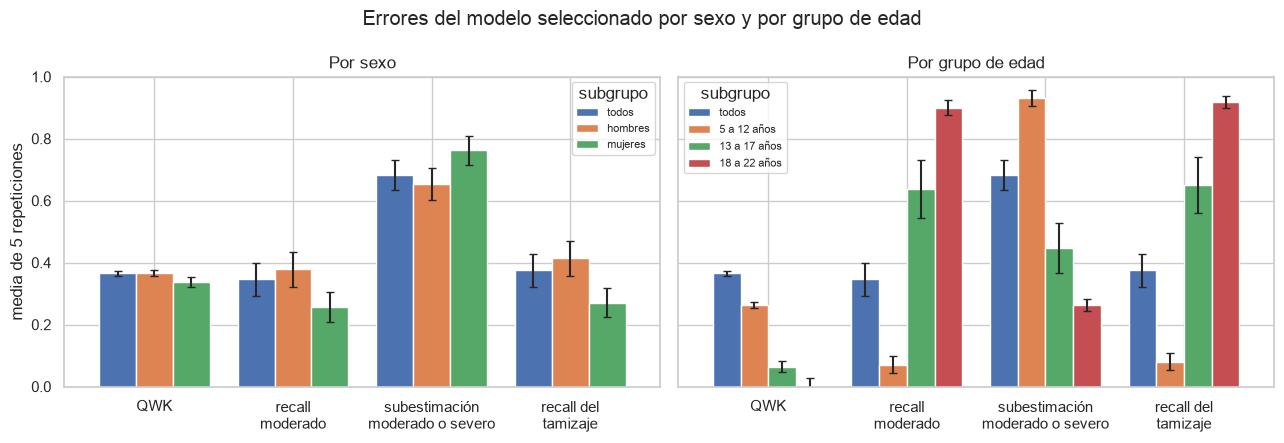

In [25]:
# Comparación gráfica de los subgrupos en las métricas de mayor interés para el
# tamizaje: media entre repeticiones y desviación como barra de error, con todos
# los participantes como referencia en cada panel.
METRICAS_FIGURA = {
    "qwk": "QWK",
    "recall_2": "recall\nmoderado",
    "underestimation": "subestimación\nmoderado o severo",
    "screening_recall": "recall del\ntamizaje",
}
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for eje, (criterio, serie) in zip(ejes, grupos.items(), strict=True):
    filas_figura = [("sexo", "todos")] + [
        (criterio, subgrupo) for subgrupo in serie.cat.categories
    ]
    medias = medias_subgrupo.loc[filas_figura, list(METRICAS_FIGURA)].droplevel(0)
    desviaciones = desviaciones_subgrupo.loc[
        filas_figura, list(METRICAS_FIGURA)
    ].droplevel(0)
    medias.rename(columns=METRICAS_FIGURA).T.plot.bar(
        yerr=desviaciones.rename(columns=METRICAS_FIGURA).T,
        ax=eje,
        capsize=3,
        rot=0,
        width=0.8,
    )
    eje.set_title(f"Por {criterio}")
    eje.set_xlabel("")
    eje.set_ylim(0, 1)
    eje.legend(title="subgrupo", fontsize=8)
ejes[0].set_ylabel("media de 5 repeticiones")
fig.suptitle("Errores del modelo seleccionado por sexo y por grupo de edad")
fig.tight_layout()
save_figure(fig, "errores_por_subgrupo", FIGURAS)
plt.show()

### Conclusión

- **Escala común.** Con todos los participantes, el QWK calculado sobre las predicciones de cada repetición es 0,365, igual a tres decimales a la media por partición, así que los subgrupos se comparan con la misma referencia de las secciones anteriores.
- **Por sexo.** La diferencia es moderada y va en la misma dirección en todas las métricas:
  - Los hombres (1.739, de ellos 302 moderados o severos) tienen un QWK de 0,367; las mujeres (997, de ellas 110 moderadas o severas), de 0,338.
  - El modelo remite al 20,6 % de los hombres y al 12,3 % de las mujeres. El recall del tamizaje es 0,413 en hombres y 0,271 en mujeres, y la subestimación de los niveles moderado y severo, 0,654 y 0,762.
  - La especificidad es mayor en mujeres (0,896 frente a 0,837). En ambos sexos, el valor predictivo positivo duplica aproximadamente la prevalencia: 0,348 frente a 17,4 % en hombres y 0,249 frente a 11,0 % en mujeres.

  Las mujeres con uso problemático se detectan menos, en línea con el coeficiente negativo del sexo de la sección 4, donde el valor 1 corresponde a las mujeres.
- **Por grupo de edad.** Las diferencias son mucho mayores y muestran que el modelo ordena a los participantes sobre todo por su edad:
  - *5 a 12 años* (2.070 participantes; 209 moderados o severos y 6 severos). El modelo casi no remite: al 2,6 % del grupo. El recall del tamizaje es 0,080 y el 93,1 % de los moderados o severos se subestima. A cambio, la especificidad es 0,980 y el valor predictivo positivo, 0,319, unas tres veces la prevalencia del grupo.
  - *13 a 17 años* (582; 181 moderados o severos y 24 severos). El modelo remite al 60,0 % del grupo, casi el doble de su prevalencia (31,1 %). El recall del tamizaje sube a 0,650, pero la especificidad cae a 0,423, y solo al 1,3 % de quienes no tienen uso problemático se le asigna el nivel ninguno.
  - *18 a 22 años* (84; 22 moderados o severos y 4 severos). El modelo asigna el nivel moderado a casi todos: remite al 91,7 %, con un recall del tamizaje de 0,918 y una especificidad de 0,084.
- **Dentro de cada grupo de edad.** El QWK es de 0,264 entre los 5 y los 12 años, 0,064 entre los 13 y los 17, y 0,002 entre los 18 y los 22. Dentro de cada grupo, las predicciones se concentran en pocos niveles (ninguno y leve en los niños; leve y moderado en los adolescentes; moderado en el grupo mayor), así que el modelo apenas distingue a los participantes de una misma edad. En los dos grupos mayores, el valor predictivo positivo es prácticamente igual a la prevalencia (0,338 frente a 31,1 % y 0,263 frente a 26,2 %): dentro de esos grupos, remitir según el modelo no es mejor que remitir al azar a la misma cantidad de participantes. El acuerdo global se explica, en buena parte, por la diferencia de prevalencia entre niños y adolescentes, que el modelo capta a través de la edad y de las variables físicas que la reflejan.
- **Nivel severo.** El recall severo es 0 en todos los subgrupos, como en el conjunto.

Los errores del modelo no se distribuyen por igual. Los niños con uso problemático casi nunca se remitirían, y la mayoría de los adolescentes sin uso problemático sí. Este es el principal riesgo de equidad de un tamizaje basado en estos indicadores. Las cifras del grupo de 18 a 22 años se basan en 84 participantes y 4 severos, así que solo indican una tendencia. Como el SII proviene del reporte de los padres, parte de la diferencia por edad y por sexo puede reflejar también lo que los padres observan, y no solo el comportamiento del modelo.

## 6. Tablas exportadas y conclusiones

Esta sección deja los resultados del notebook listos para el informe:

- **Tablas agregadas.** Las tablas de cada sección se guardan en CSV, con las mismas etiquetas que se muestran en el notebook. Antes de guardarlas se verifica que ninguna tenga columnas de identificación o de posición de participantes y que todas sean pequeñas, como corresponde a resúmenes.
- **Resumen para las recomendaciones.** Una tabla reúne las métricas centrales del objetivo 3, cada una con su media, su desviación entre repeticiones, su intervalo del 95 % y el número de participantes sobre el que se calcula, además de la sección del notebook de donde proviene. Es el insumo de la tabla de recomendaciones del objetivo 5, que vincula cada recomendación con su métrica, su variabilidad y su limitación.
- **Figuras.** Se verifica que las figuras del notebook estén en su carpeta.

Al final se libera el caché del preprocesamiento de este notebook, que solo se usaría si hubiera que volver a ajustar alguna partición.

In [26]:
# Resumen de las métricas centrales del objetivo 3: desempeño por nivel (sección
# 2) y escenario de tamizaje (sección 3). El intervalo del recall severo es el de
# Wilson, porque el del remuestreo no informa cuando no hay aciertos; el QWK se
# reporta solo con su desviación entre repeticiones.
remision_severos = remision_por_repeticion[SEVERE_LEVEL]
metricas_objetivo_5 = pd.concat(
    [
        por_repeticion[["qwk", "recall_2", "recall_3", "underestimation"]],
        tamizaje_por_repeticion,
        remision_severos["share"].rename("severe_referred"),
    ],
    axis="columns",
)
intervalos_objetivo_5 = {
    "recall_2": tuple(
        resumen_desempeno.loc["recall_2", ["interval_low", "interval_high"]]
    ),
    "recall_3": (
        aciertos_severo["wilson_low"].mean(),
        aciertos_severo["wilson_high"].mean(),
    ),
    "underestimation": tuple(
        resumen_desempeno.loc["underestimation", ["interval_low", "interval_high"]]
    ),
    **{
        metrica: tuple(
            bootstrap_tamizaje.loc[metrica, ["interval_low", "interval_high"]]
        )
        for metrica in tamizaje_por_repeticion.columns
    },
    "severe_referred": participant_bootstrap_ci(
        participant_referral_rates(predicciones, SEVERE_LEVEL)
    ),
}
n_moderados = int((y == NIVEL_MODERADO).sum())
n_severos = int((y == SEVERE_LEVEL).sum())
resumen_objetivo_5 = metric_summary(
    metricas_objetivo_5,
    intervals=intervalos_objetivo_5,
    sizes={
        "recall_2": n_moderados,
        "recall_3": n_severos,
        "underestimation": n_moderados + n_severos,
        "recall": n_positivos,
        "specificity": len(y) - n_positivos,
        "referred_share": len(y),
        "severe_referred": n_severos,
    },
)
resumen_objetivo_5.insert(
    0,
    "sección",
    ["2"] * 4 + ["3"] * (len(resumen_objetivo_5) - 4),
)
resumen_objetivo_5["intervalo"] = [
    "Wilson"
    if metrica == "recall_3"
    else "remuestreo de participantes"
    if metrica in intervalos_objetivo_5
    else "sin intervalo"
    for metrica in resumen_objetivo_5.index
]
ETIQUETAS_OBJETIVO_5 = {
    **ETIQUETAS_METRICAS,
    "recall": "recall del tamizaje",
    "specificity": "especificidad del tamizaje",
    "ppv": "valor predictivo positivo del tamizaje",
    "referred_share": "proporción remitida",
    "severe_referred": "proporción de severos remitidos",
}
resumen_objetivo_5 = resumen_objetivo_5.rename(
    index=ETIQUETAS_OBJETIVO_5, columns=ETIQUETAS_RESUMEN
).rename_axis("métrica")
resumen_objetivo_5.round(3)

,sección,media,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior,participantes,intervalo
métrica,,,,,,,
QWK,2,0.365,0.007,NaN,NaN,<NA>,sin intervalo
recall moderado,2,0.346,0.052,0.303,0.389,378,remuestreo de participantes
recall severo,2,0.000,0.000,0.000,0.102,34,Wilson
subestimación moderado o severo,2,0.683,0.048,0.643,0.722,412,remuestreo de participantes
recall del tamizaje,3,0.375,0.052,0.334,0.418,412,remuestreo de participantes
especificidad del tamizaje,3,0.860,0.025,0.847,0.872,2324,remuestreo de participantes
valor predictivo positivo del tamizaje,3,0.323,0.013,0.283,0.361,<NA>,remuestreo de participantes
proporción remitida,3,0.176,0.029,0.163,0.188,2736,remuestreo de participantes
proporción de severos remitidos,3,0.706,0.055,0.565,0.835,34,remuestreo de participantes


In [27]:
# Tablas agregadas del notebook, para el informe, con las mismas etiquetas que se
# muestran: ninguna contiene filas por participante.
NOMBRES_MATRICES = {
    "participantes por repetición": "matriz_confusion_conteos",
    "proporción de cada nivel real": "matriz_confusion_proporciones",
}
TABLAS_EXPORTADAS = {
    "resumen_objetivo_5": resumen_objetivo_5,
    "desempeno_por_repeticion": pd.concat(
        [por_repeticion.rename_axis("repetición"), resumen_repeticiones]
    ).rename(columns=ETIQUETAS_METRICAS),
    "desempeno_por_nivel": resumen_desempeno.rename(
        index=ETIQUETAS_METRICAS, columns=ETIQUETAS_RESUMEN
    ).rename_axis("métrica"),
    **{
        NOMBRES_MATRICES[titulo]: matriz.set_axis(etiquetas_niveles, axis=0)
        .set_axis(etiquetas_niveles, axis=1)
        .rename_axis(index="nivel real", columns="nivel asignado")
        for titulo, matriz in matrices.items()
    },
    "severo_aciertos": aciertos_severo.rename(
        columns={
            "cases": "casos severos",
            "hits": "aciertos",
            "recall": "recall",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    ).rename_axis("repetición"),
    "severo_distribucion": distribucion_severo.rename_axis(columns="nivel asignado"),
    "tamizaje_por_repeticion": pd.concat(
        [
            tamizaje_por_repeticion.rename_axis("repetición"),
            tamizaje_por_repeticion.agg(["mean", "std"]).rename(
                index={"mean": "media", "std": "desviación"}
            ),
        ]
    ).rename(columns=ETIQUETAS_TAMIZAJE),
    "tamizaje_resumen": resumen_tamizaje.rename(
        index=ETIQUETAS_TAMIZAJE, columns=ETIQUETAS_RESUMEN
    ).rename_axis("métrica"),
    "tamizaje_remision_por_nivel": remision_por_nivel,
    "tamizaje_severos_remitidos": remision_severos.rename(
        columns={
            "cases": "casos severos",
            "referred": "remitidos",
            "share": "proporción remitida",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    ).rename_axis("repetición"),
    "tamizaje_consistencia": pd.DataFrame(
        {
            NIVELES_SII[nivel]: referral_consistency(
                participant_referral_rates(predicciones, nivel)
            )
            for nivel in UNDERESTIMATION_LEVELS
        }
    )
    .T.rename(
        columns={
            "always": "remitidos en todas las repeticiones",
            "never": "en ninguna",
            "sometimes": "en algunas",
            "participants": "participantes",
        }
    )
    .rename_axis("nivel real"),
    "shap_importancia_variables": importancia_variables,
    "shap_ranking_por_repeticion": ranking_por_repeticion,
    "shap_estabilidad_pares": ranking_stability(importancia)
    .rename(
        columns={
            "repeat_a": "repetición a",
            "repeat_b": "repetición b",
            "spearman": "Spearman",
        }
    )
    .set_index(["repetición a", "repetición b"]),
    "shap_estabilidad_criterio": pd.Series(
        {
            "Spearman mínimo": estabilidad["min_spearman"],
            "Spearman mediano": estabilidad["median_spearman"],
            "criterio de Spearman mínimo": STABILITY_MIN_SPEARMAN,
            f"mismas {STABILITY_TOP_K} variables principales": estabilidad[
                "same_top_k"
            ],
            "el orden se mantiene": estabilidad["stable"],
        },
        name="valor",
    )
    .rename_axis("criterio")
    .to_frame(),
    "shap_importancia_instrumentos": tablas_agregadas["instrumento"],
    "shap_importancia_grupos": tablas_agregadas["grupo"],
    "shap_direccion": direccion,
    "shap_relacion_edad": relacion_edad,
    "shap_actigrafia_imputada": actigrafia.rename_axis("valores de actigrafía"),
    "subgrupos_tamanos": tamanos,
    "subgrupos_media": medias_subgrupo.rename(columns=ETIQUETAS_SUBGRUPOS),
    "subgrupos_desviacion": desviaciones_subgrupo.rename(columns=ETIQUETAS_SUBGRUPOS),
    "subgrupos_tamizaje_media": medias_tamizaje.rename(columns=ETIQUETAS_TAMIZAJE),
    "subgrupos_tamizaje_desviacion": desviaciones_tamizaje.rename(
        columns=ETIQUETAS_TAMIZAJE
    ),
}
# Control de privacidad: ninguna tabla tiene columnas de identificación o de
# posición de participantes, y todas son pequeñas, como corresponde a resúmenes.
for nombre, tabla in TABLAS_EXPORTADAS.items():
    columnas = {str(c).lower() for c in [*tabla.columns, *tabla.index.names]}
    assert not columnas & {"id", "position", "posición"}, nombre
    assert len(tabla) < 100, nombre

TABLAS.mkdir(parents=True, exist_ok=True)
for nombre, tabla in TABLAS_EXPORTADAS.items():
    tabla.to_csv(TABLAS / f"{nombre}.csv")
RAIZ = TABLES_DIR.parents[1]
print(f"{len(TABLAS_EXPORTADAS)} tablas guardadas en {TABLAS.relative_to(RAIZ)}")

# Las figuras del notebook quedan en su carpeta de reports/figures.
FIGURAS_NOTEBOOK = (
    "matriz_confusion",
    "remision_por_nivel",
    "importancia_variables",
    "contribuciones_shap_repeticion",
    "errores_por_subgrupo",
)
assert all((FIGURAS / f"{nombre}.png").exists() for nombre in FIGURAS_NOTEBOOK)
print(
    f"{len(FIGURAS_NOTEBOOK)} figuras en {FIGURAS.relative_to(RAIZ)}: "
    + ", ".join(FIGURAS_NOTEBOOK)
)

# El caché de Pipeline(memory=...) solo se usaría para reajustar particiones.
clear_pipeline_memory(CARPETA_MEMORIA)

26 tablas guardadas en reports/tables/04_interpretabilidad_errores
5 figuras en reports/figures/04_interpretabilidad_errores: matriz_confusion, remision_por_nivel, importancia_variables, contribuciones_shap_repeticion, errores_por_subgrupo


### Verificación del criterio de cumplimiento

La Tabla 2 de la formulación define el criterio de cumplimiento del objetivo 3. Cada uno de sus elementos se cumple en este notebook así:

| Elemento del criterio | Sección | Figuras | Tablas exportadas |
|---|---|---|---|
| Matriz de confusión | 2 | `matriz_confusion` | `matriz_confusion_conteos`, `matriz_confusion_proporciones` |
| Recall por nivel de severidad y tasa de subestimación | 2 | `matriz_confusion` | `desempeno_por_repeticion`, `desempeno_por_nivel` |
| Distribución de los casos severos entre los niveles asignados | 2 | — | `severo_aciertos`, `severo_distribucion` |
| Escenario de tamizaje: recall, especificidad, valor predictivo positivo y proporción remitida | 3 | `remision_por_nivel` | `tamizaje_por_repeticion`, `tamizaje_resumen`, `tamizaje_remision_por_nivel`, `tamizaje_severos_remitidos`, `tamizaje_consistencia` |
| Contribución de las variables del modelo seleccionado y estabilidad de su orden | 4 | `importancia_variables`, `contribuciones_shap_repeticion` | tablas con prefijo `shap_` |
| Comparación de los errores entre sexos y grupos de edad | 5 | `errores_por_subgrupo` | tablas con prefijo `subgrupos_` |
| Métricas centrales con su variabilidad, para el objetivo 5 | 6 | — | `resumen_objetivo_5` |

### Conclusión

Este notebook desarrolló el objetivo específico 3: analizó el desempeño por nivel de severidad del modelo seleccionado, con énfasis en su capacidad para no subestimar los casos severos, e identificó con valores SHAP las variables con mayor contribución a sus estimaciones.

- **Desempeño por nivel.** El QWK medio es 0,365, con una desviación entre repeticiones de 0,007. El modelo reconoce mejor a los participantes sin uso problemático (recall de 0,658) que a los leves (0,384) y los moderados (0,346). El 68,3 % de los moderados o severos recibe un nivel inferior al real. El nivel severo no se asigna a ningún participante, así que su recall es 0, con una cota superior de Wilson de 0,102. Aun así, el 70,6 % de los severos se ubica en el nivel moderado.
- **Escenario de tamizaje.** Remitiendo desde el nivel moderado, el modelo remite al 17,6 % de los participantes, con un recall de 0,375, una especificidad de 0,860 y un valor predictivo positivo de 0,323. El recall y el valor predictivo positivo duplican los de una remisión al azar de la misma proporción. Se remite a 24 de los 34 participantes severos en promedio (70,6 %; intervalo del 95 % de 56,5 % a 83,5 %). La principal pérdida está en los moderados: más de la mitad no se remite en ninguna repetición.
- **Contribución de las variables.** La edad es la variable con mayor contribución en todas las repeticiones, seguida del sexo. Las variables físicas tienen una contribución conjunta alta, pero están muy correlacionadas con la edad. Por eso, el orden de importancia de cada una no se mantiene entre repeticiones con el criterio fijado de antemano: el Spearman mínimo es 0,694, frente al umbral de 0,9. A nivel de grupo, el orden sí es estable. La actigrafía aporta poco, y en el 69,9 % de los participantes sus valores son imputados.
- **Errores por subgrupo.** Los errores dependen sobre todo de la edad. Entre los 5 y los 12 años, el modelo casi no remite y detecta al 8,0 % de los moderados o severos. Entre los 13 y los 17, remite al 60,0 % del grupo, con una especificidad de 0,423. Dentro de cada grupo de edad, el QWK es de 0,264 o menos. En los grupos de 13 a 17 y de 18 a 22 años, el valor predictivo positivo es igual a la prevalencia. Por sexo, las mujeres con uso problemático se detectan menos que los hombres (recall del tamizaje de 0,271 frente a 0,413).

En conjunto, la capacidad del modelo para estimar la severidad proviene en buena parte de la edad y de las variables físicas que la reflejan, y no de una distinción entre participantes de una misma edad. En un tamizaje que remite desde el nivel moderado, la mayoría de los casos severos llegaría a una evaluación, pero el costo se reparte de forma desigual: los niños con uso problemático quedarían sin detectar y muchos adolescentes sin el problema serían remitidos.

**Limitaciones.**

- Las métricas tienen el sesgo optimista de reportar el desempeño con las particiones usadas en la selección.
- Con 34 casos severos, las cifras de ese nivel tienen intervalos amplios.
- El SII proviene del reporte de los padres, y la muestra del Healthy Brain Network es clínica y no representativa de la población general.
- Los valores SHAP describen el modelo y no efectos causales, y en los participantes sin un instrumento se calculan sobre valores imputados.
- El análisis por subgrupo es descriptivo, y el grupo de 18 a 22 años tiene solo 84 participantes.
- No existe un umbral clínico de desempeño aceptable, así que estos resultados son evidencia exploratoria sobre el potencial de los indicadores, no una validación de un tamizaje.